# Descriptive Implementation of Regulizers for Polynomial Regression

Importing Libraries 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Generating Dataset

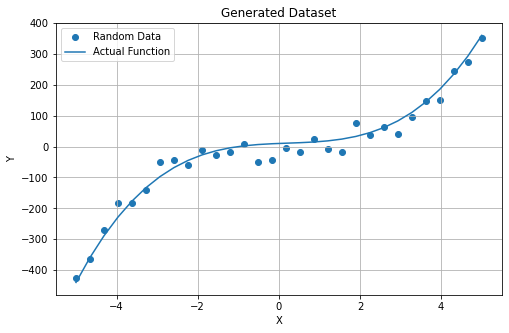

In [2]:
np.random.seed(42)

# Number of data points
n = 30

# Generate X
X = np.linspace(-5, 5, n)

# Actual underlying function
y_true = 3 * X**3 - 2 * X**2 + 5 * X + 10

# Add random noise
noise = np.random.normal(0, 30, n)

# Final dataset
y = y_true + noise

# Plot the generated data
plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Random Data")
plt.plot(X, y_true, label="Actual Function")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Generated Dataset")

plt.legend()
plt.grid(True)
plt.show()

Mixing

In [3]:
# Shuffle indices
indices = np.arange(n)
np.random.shuffle(indices)

# 80% training
train_size = int(0.8 * n)

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X[train_indices]
y_train = y[train_indices]

X_test = X[test_indices]
y_test = y[test_indices]

print("Training samples :", len(X_train))
print("Testing samples  :", len(X_test))

Training samples : 24
Testing samples  : 6


Poly Regg

In [4]:
def polynomial_features(X, degree):

    X = np.asarray(X)

    features = []

    for i in range(degree + 1):
        features.append(X ** i)

    return np.column_stack(features)

In [5]:
degree = 15

X_poly = polynomial_features(X_train, degree)

print("Shape of polynomial feature matrix:")
print(X_poly.shape)

Shape of polynomial feature matrix:
(24, 16)


In [10]:
def polynomial_regression(X, y, degree):

    # Create polynomial feature matrix
    X_poly = polynomial_features(X, degree)

    # Calculate theta using normal equation
    theta = np.linalg.pinv(
        X_poly.T @ X_poly
    ) @ X_poly.T @ y

    # IMPORTANT: return the coefficients
    return theta

In [11]:
degree = 15

theta_poly = polynomial_regression(
    X_train,
    y_train,
    degree
)

print("Polynomial coefficients:")
print(theta_poly)

Polynomial coefficients:
[-2.56396360e-06  8.00675639e-06 -2.06058929e-05  7.16321650e-05
 -1.59880955e-04  5.89683562e-04 -1.05178194e-03  4.01543357e-03
 -4.46890865e-03  1.74180092e-02  5.51909079e-04 -2.40468154e-03
 -2.48390467e-05  1.11709903e-04  3.93264380e-07 -1.73329711e-06]


In [12]:
def predict(X, theta):

    degree = len(theta) - 1

    X_poly = polynomial_features(X, degree)

    return X_poly @ theta

In [13]:
y_poly_test = predict(X_test, theta_poly)

In [16]:
def mean_squared_error(y_actual, y_predicted):

    return np.mean((y_actual - y_predicted) ** 2)

In [17]:
poly_mse = mean_squared_error(
    y_test,
    y_poly_test
)

print("Polynomial Regression MSE:", poly_mse)

Polynomial Regression MSE: 1552.7195552008618


Ridge Regulization

In [18]:
def ridge_regression(X, y, degree, alpha):

    # Polynomial features
    X_poly = polynomial_features(X, degree)

    # Number of features
    n_features = X_poly.shape[1]

    # Identity matrix
    I = np.eye(n_features)

    # Do not regularize the intercept
    I[0, 0] = 0

    # Ridge equation
    theta = np.linalg.pinv(
        X_poly.T @ X_poly + alpha * I
    ) @ X_poly.T @ y

    return theta

In [19]:
degree = 15

alpha_ridge = 10

theta_ridge = ridge_regression(
    X_train,
    y_train,
    degree,
    alpha_ridge
)

y_ridge_test = predict(
    X_test,
    theta_ridge
)

ridge_mse = mean_squared_error(
    y_test,
    y_ridge_test
)

print("Ridge Regression MSE:", ridge_mse)

Ridge Regression MSE: 1552.7193681912702


Lasso Regularization

In [20]:
def soft_thresholding(z, threshold):

    if z > threshold:
        return z - threshold

    elif z < -threshold:
        return z + threshold

    else:
        return 0.0

In [21]:
def lasso_regression(X, y, degree, alpha, iterations=10000):

    # Polynomial feature matrix
    X_poly = polynomial_features(X, degree)

    n_samples, n_features = X_poly.shape

    # Initialize coefficients
    theta = np.zeros(n_features)

    # Normalize columns except intercept
    X_scaled = X_poly.copy()

    for j in range(1, n_features):

        norm = np.sqrt(np.sum(X_scaled[:, j] ** 2))

        if norm != 0:
            X_scaled[:, j] = X_scaled[:, j] / norm

    # Coordinate descent
    for iteration in range(iterations):

        theta_old = theta.copy()

        # Calculate predictions
        prediction = X_scaled @ theta

        for j in range(n_features):

            # Do not regularize intercept
            if j == 0:

                residual = y - (X_scaled @ theta - X_scaled[:, j] * theta[j])

                theta[j] = np.sum(
                    X_scaled[:, j] * residual
                ) / np.sum(
                    X_scaled[:, j] ** 2
                )

            else:

                residual = y - (
                    X_scaled @ theta -
                    X_scaled[:, j] * theta[j]
                )

                rho = np.sum(
                    X_scaled[:, j] * residual
                )

                denominator = np.sum(
                    X_scaled[:, j] ** 2
                )

                theta[j] = soft_thresholding(
                    rho,
                    alpha
                ) / denominator

        # Check convergence
        if np.max(np.abs(theta - theta_old)) < 1e-6:
            break

    # Convert coefficients back
    for j in range(1, n_features):

        norm = np.sqrt(
            np.sum(X_poly[:, j] ** 2)
        )

        if norm != 0:
            theta[j] = theta[j] / norm

    return theta

In [22]:
degree = 15

alpha_lasso = 10

theta_lasso = lasso_regression(
    X_train,
    y_train,
    degree,
    alpha_lasso
)

y_lasso_test = predict(
    X_test,
    theta_lasso
)

lasso_mse = mean_squared_error(
    y_test,
    y_lasso_test
)

print("Lasso Regression MSE:", lasso_mse)

Lasso Regression MSE: 974.4605709075353


Plotting 

In [23]:
X_plot = np.linspace(
    -5,
    5,
    500
)

y_poly_curve = predict(
    X_plot,
    theta_poly
)

y_lasso_curve = predict(
    X_plot,
    theta_lasso
)

y_ridge_curve = predict(
    X_plot,
    theta_ridge
)

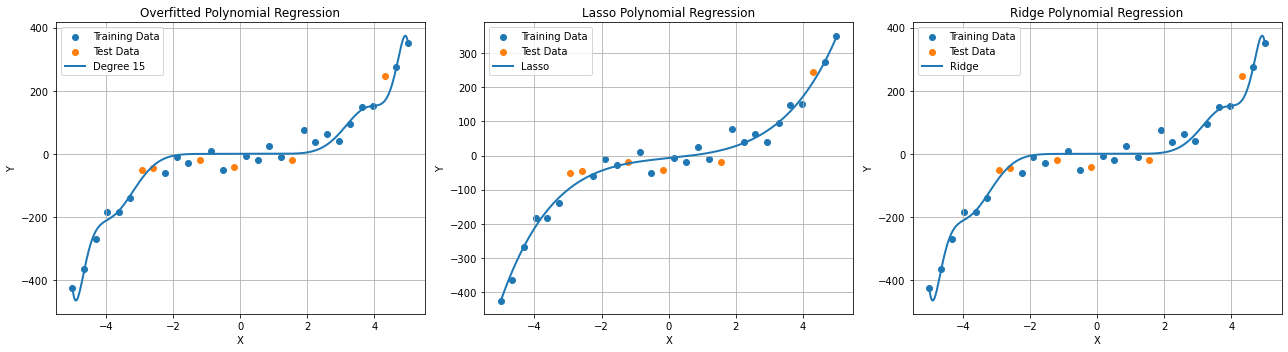

In [24]:
plt.figure(figsize=(18, 5))


# ==========================================================
# 1. Overfitted Polynomial Regression
# ==========================================================

plt.subplot(1, 3, 1)

plt.scatter(
    X_train,
    y_train,
    label="Training Data"
)

plt.scatter(
    X_test,
    y_test,
    label="Test Data"
)

plt.plot(
    X_plot,
    y_poly_curve,
    linewidth=2,
    label="Degree 15"
)

plt.title("Overfitted Polynomial Regression")

plt.xlabel("X")
plt.ylabel("Y")

plt.legend()
plt.grid(True)


# ==========================================================
# 2. Lasso Regression
# ==========================================================

plt.subplot(1, 3, 2)

plt.scatter(
    X_train,
    y_train,
    label="Training Data"
)

plt.scatter(
    X_test,
    y_test,
    label="Test Data"
)

plt.plot(
    X_plot,
    y_lasso_curve,
    linewidth=2,
    label="Lasso"
)

plt.title("Lasso Polynomial Regression")

plt.xlabel("X")
plt.ylabel("Y")

plt.legend()
plt.grid(True)


# ==========================================================
# 3. Ridge Regression
# ==========================================================

plt.subplot(1, 3, 3)

plt.scatter(
    X_train,
    y_train,
    label="Training Data"
)

plt.scatter(
    X_test,
    y_test,
    label="Test Data"
)

plt.plot(
    X_plot,
    y_ridge_curve,
    linewidth=2,
    label="Ridge"
)

plt.title("Ridge Polynomial Regression")

plt.xlabel("X")
plt.ylabel("Y")

plt.legend()
plt.grid(True)


plt.tight_layout()
plt.show()